# Problem 1.3: estimating fractal dimensions in images

In [ ]:
import numpy as np
import numpy.linalg as la
import imageio.v3 as iio
import scipy.ndimage as img
import matplotlib.pyplot as plt

## Task 1.3.1

### Box counting

Procedure:
1. apply binarization (foreground pixels 1, background pixels 0)
2. specify set S of scaling factors 0 < s < 1; for each s of S: cover image with boxes of size sw x sh; count boxes with at least one foreground pixel (n)
3. plot log(n) against log(1/s) and fit a line; slope D represents fractal dimension we are after

-> Estimating fractal dimension of object in image is linear regression problem. can be solved with lsq

In [77]:
def binarize(imgF):
    '''
    turn grey scale image into binary image such that
    1 = foreground pixel
    0 = background pixel
    '''
    imgB = np.abs(img.gaussian_filter(imgF, sigma=0.50) - \
    img.gaussian_filter(imgF, sigma=1.00))
    return img.binary_closing(np.where(imgB < 0.1*imgB.max(), 0, 1))


def boxCounting(img, name):
    # Step 1: Binarize the images
    imgBin = binarize(img)

    w_old = int(imgBin.shape[0])
    h_old = int(imgBin.shape[1])

    L = int(np.log2(imgBin.shape[0]))

    result = {}
    resultLog = {}

    # Step 2: Loop over box sizes
    for l in range(1, L-1):
        # Step 2.1: Specify S
        s_l = 1/(2**l) 

        # Prepare count and box size
        count = 0
        h = int(s_l * h_old)
        w = int(s_l * w_old)

        # Step 2.2: Overlay boxes on binary image
        for i in range(0, imgBin.shape[0], h):
            for j in range(0, imgBin.shape[1], w):
                if np.any(imgBin[i:i+h, j:j+w] == 1):
                    count += 1
        
        result[s_l] = count
        resultLog[np.log(1/s_l)] = np.log(count)

    # Step 3: fit line to log-log datapoints and get slope D
    D, b = fitLine(resultLog)
    
    # Step 4: Plot the log-log plot and fitted line
    plotBoxCounting(resultLog, D, b, f'Box Counting Results for {name}')
    
    return result, D


def fitLine(logDict):
    # Formula: D*x + b = y
    x = np.array(list(logDict.keys()))      # log(1/s_l) values
    y = np.array(list(logDict.values()))    # log(n) values

    # Create matX for lsq from x and ones 
    # D is multiplied by x and b is multiplied by 1
    matX = np.vstack([x, np.ones(len(x))]).T

    # Solve for D and b using least squares
    # Formula ||Xw - y||^2 for w = [D, b]
    D, b = la.lstsq(matX, y, rcond=None)[0]
    return D, b


def plotBoxCounting(logDict, D, b, title):
    x = np.array(list(logDict.keys()))
    y = np.array(list(logDict.values()))
    
    plt.figure()
    plt.plot(x, y, 'o', label='datapoints')
    plt.plot(x, D*x + b, '-', label=f'D = {D:.3f} (fractal dimension)')
    plt.xlabel('log(1/s)')
    plt.ylabel('log(n)')
    plt.title(title)
    plt.legend()
    plt.show()

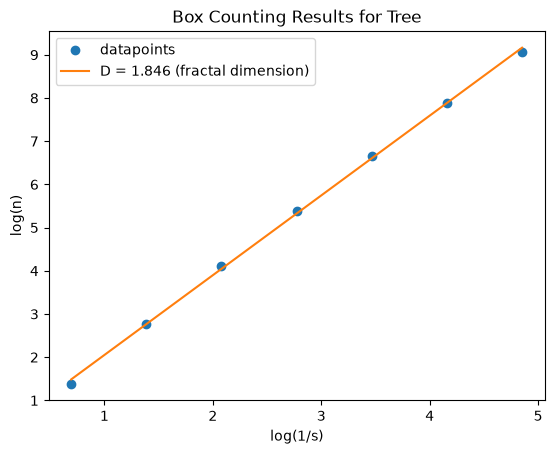

Tree boxes: {0.5: 4, 0.25: 16, 0.125: 61, 0.0625: 218, 0.03125: 777, 0.015625: 2679, 0.0078125: 8685}
Tree dimension: 1.8464


In [78]:
imgTree = iio.imread('imageTree.png', mode='L').astype(float)
treeBoxes, D_tree = boxCounting(imgTree, 'Tree')
print('Tree boxes: ' + str(treeBoxes))
print('Tree dimension: ' + str(f'{D_tree:.4f}'))

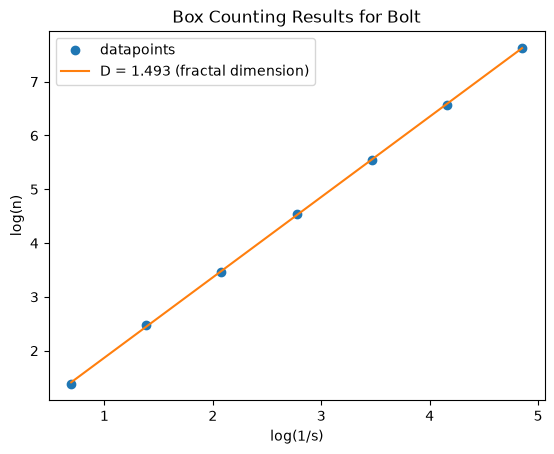

Bolt boxes: {0.5: 4, 0.25: 12, 0.125: 32, 0.0625: 94, 0.03125: 254, 0.015625: 716, 0.0078125: 2063}
Bolt dimension: 1.4935


In [79]:
imgBolt = iio.imread('imageBolt.png', mode='L').astype(float)
boltBoxes, D_bolt = boxCounting(imgBolt, 'Bolt')
print('Bolt boxes: ' + str(boltBoxes))
print('Bolt dimension: ' + str(f'{D_bolt:.4f}'))